In [1]:
using LinearAlgebra
using Plots

Metodo ADI para ecuacion de calor con fuente

Iteracion : Iteración ADI:

$$\begin{aligned}
\text{primer medio paso: } & A_x U^{n+1/2} = U^n B_y + F^{n+1/2} \\
\text{segundo medio paso: } & U^{n+1} A_y = B_x U^{n+1/2} + F^{n+1/2}
\end{aligned}$$

  3.567872 seconds (3.21 M allocations: 216.970 MiB, 9.82% gc time, 99.84% compilation time)


[ Info: Saved animation to c:\Users\mauri\OneDrive\Escritorio\tps_numerico\solucion_ADI.gif


Plots.AnimatedGif("c:\\Users\\mauri\\OneDrive\\Escritorio\\tps_numerico\\solucion_ADI.gif")
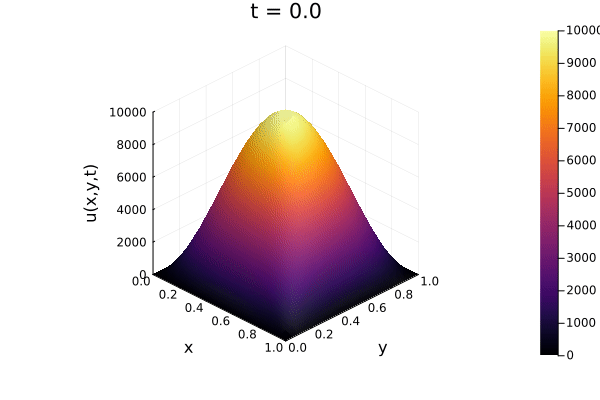

In [2]:
function ADI_calor(hx, hy, dt, T, a, g, f)

    # Cantidad de nodos y pasos temporales
    Nx = round(Int, 1/hx)
    Ny = round(Int, 1/hy)
    Nt = round(Int, T/dt)

    # Malla espacial
    x = 0:hx:1
    y = 0:hy:1

    # Condición inicial
    U = [g(xi, yj) for xi in x, yj in y]

    # Condición de borde
    U[1, :] .= 0
    U[end, :] .= 0
    U[:, 1] .= 0
    U[:, end] .= 0

    # Parámetros del ADI
    rx = a*dt/hx^2
    ry = a*dt/hy^2

    # MATRICES IMPLÍCITAS (Lado Izquierdo de la ecuación)
    Ax = Tridiagonal(-rx/2 * ones(Nx-2), (1 + rx) * ones(Nx-1), -rx/2 * ones(Nx-2))
    Ay = Tridiagonal(-ry/2 * ones(Ny-2), (1 + ry) * ones(Ny-1), -ry/2 * ones(Ny-2))

    # MATRICES EXPLÍCITAS (Lado Derecho de la ecuación)
    Bx = Tridiagonal(rx/2 * ones(Nx-2), (1 - rx) * ones(Nx-1), rx/2 * ones(Nx-2))
    By = Tridiagonal(ry/2 * ones(Ny-2), (1 - ry) * ones(Ny-1), ry/2 * ones(Ny-2))

    # Guardamos la solución en todos los tiempos
    sol = zeros(Nx+1, Ny+1, Nt+1)

    # Solución inicial
    sol[:, :, 1] = U

            #defino los x,y interiores
        X_int = x[2:Nx]
        Y_int = y[2:Ny]' # el ' transpone al vector

    # Evolución temporal
    for n = 1:Nt

        t = (n-1)*dt
        t_medio = t + dt/2

        F_medio = (dt/2) .* f.(X_int, Y_int, t_medio)

        U_int = U[2:Nx,2:Ny]

        #1er medio paso (Implícito en x, explícito en Y)

        DER1 = U_int * By .+ F_medio

        U_medio_int = Ax \ DER1

        #2do medio paso (Implicito en Y, explicito en X)

        DER2 =  Bx * U_medio_int .+ F_medio

        U_nuevo_int = DER2/Ay #el / en julia es equivalente a hacer (Ay' \ DER2')' que seria una manera para despejar el U nuevo

        U[2:Nx, 2:Ny] = U_nuevo_int

        sol[:,:,n+1] .= U
    end
    return x, y, sol
end

# datos de ejemplo


hx = 0.05
hy = 0.05

dt = 0.005
T = 0.15

a = 1.0


# Condición inicial
g(x,y) = 10000*sin(π*x)*sin(π*y)


# Término fuente
f(x,y,t) = 0

@time x, y, sol = ADI_calor(hx, hy, dt, T, a, g, f)

#ANIMACIÓN


anim = @animate for n in 1:size(sol, 3)

  surface(
        x,
        y,
        sol[:, :, n]',
        xlabel = "x",
        ylabel = "y",
        zlabel = "u(x,y,t)",
        title = "t = $(round((n-1)*dt, digits=2))",

         #Eje z fijo
        zlims = (0, 10000),

        camera = (45, 30)
    )

end


gif(anim, "solucion_ADI.gif", fps=20)


EXPLICITO.

iteracion: $$U^{n+1} = U^n + r_x A_x U^n + r_y U^n A_y + \Delta t F_n$$



In [3]:

function explicito_calor(hx, hy, dt, T, a, g, f)

    # Cantidad de nodos y pasos temporales
    Nx = round(Int, 1/hx)
    Ny = round(Int, 1/hy)
    Nt = round(Int, T/dt)

    # Malla espacial
    x = 0:hx:1
    y = 0:hy:1

    # Condición inicial
    U = [g(xi, yj) for xi in x, yj in y]

    # Condición de borde
    U[1, :] .= 0
    U[end, :] .= 0
    U[:, 1] .= 0
    U[:, end] .= 0

    # Parámetros del método explícito
    rx = a*dt/hx^2
    ry = a*dt/hy^2

    # Cantidad de puntos interiores
    nx = Nx - 1
    ny = Ny - 1

    # Matrices tridiagonales de diferencias segundas
    Ax = Tridiagonal( ones(nx-1), -2 * ones(nx),ones(nx-1))

    Ay = Tridiagonal( ones(ny-1),-2 * ones(ny), ones(ny-1))

    # Guardamos la solución en todos los tiempos
    sol = zeros(Nx+1, Ny+1, Nt+1)

    # Solución inicial
    sol[:, :, 1] = U

    X_int = x[2:Nx]
    Y_int = y[2:Ny]' # el ' transpone al vector

    # Evolución temporal
    for n = 1:Nt

        t = (n-1)*dt

        # Parte interior de U
        Uint = U[2:Nx, 2:Ny]

        # Fuente
        F = f.(X_int,Y_int,t)

        # Paso explícito
        U_nuevo_int = Uint .+ rx .* Ax * Uint .+ ry .* Uint * Ay .+ dt .* F #sin poner los " . " a veces se me bugeaba

        # Colocamos los valores interiores
        U[2:Nx, 2:Ny] = U_nuevo_int

        # Guardo

        sol[:, :, n+1] = U

    end

    return x, y, sol

end

explicito_calor (generic function with 1 method)

Analisis de la estabilidad. Condicion : rx + ry <= 1/2

Ejemplos de estabilidad e inestabilidad con el metodo explicito

  2.307215 seconds (1.79 M allocations: 132.772 MiB, 4.05% gc time, 99.18% compilation time)
Cálculo terminado
rx = 0.23999999999999994
ry = 0.23999999999999994
rx + ry = 0.47999999999999987


[ Info: Saved animation to c:\Users\mauri\OneDrive\Escritorio\tps_numerico\estable.gif


Plots.AnimatedGif("c:\\Users\\mauri\\OneDrive\\Escritorio\\tps_numerico\\estable.gif")
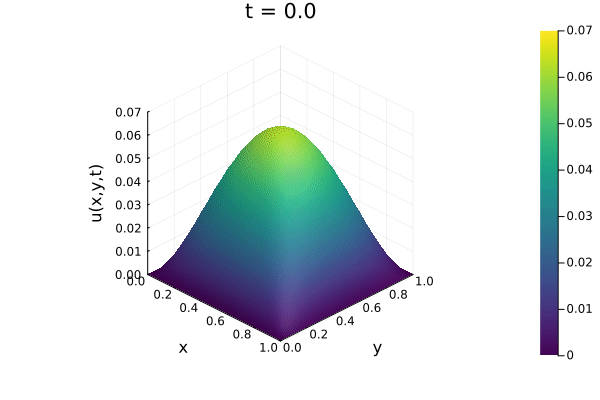

In [4]:
#EJEMPLO 1 EXPLICITO  ESTABLE
a = 1.0
hx = 0.05
hy = 0.05

dt = 0.0006       # ESTABLE (dt limite es 0.000625)
T = 0.4

# Dato inicial
g(x,y) = (x - x^2) * (y - y^2)

# Fuente
f(x,y,t) = 0.0


# Solución numérica
@time x, y, sol = explicito_calor(hx, hy, dt, T, a, g, f)

println("Cálculo terminado")


# Parámetros de estabilidad
rx = a*dt/hx^2
ry = a*dt/hy^2

println("rx = ", rx)
println("ry = ", ry)
println("rx + ry = ", rx + ry)


num_frames = 60

indices = round.(
    Int,
    range(1, size(sol, 3), length=num_frames)
)

anim = @animate for n in indices

    t = (n-1)*dt

    surface(
    x,
    y,
    sol[:, :, n]',
    xlabel = "x",
    ylabel = "y",
    zlabel = "u(x,y,t)",
    title = "t = $(round(t, digits=3))",

    xlims = (0, 1),
    ylims = (0, 1),
    zlims = (0, 0.07),

    # Fijo también la escala de colores
    clims = (0, 0.07),

    camera = (45, 30),

    # Para que no se vea casi todo negro
    c = :viridis,

    label = false
)

end

gif(anim, "estable.gif", fps=15)



  0.467200 seconds (444.63 k allocations: 21.812 MiB, 99.78% compilation time: 100% of which was recompilation)
rx = 3.999999999999999
ry = 3.999999999999999
rx + ry = 7.999999999999998


[ Info: Saved animation to /content/inestabilidad.gif


Plots.AnimatedGif("/content/inestabilidad.gif")
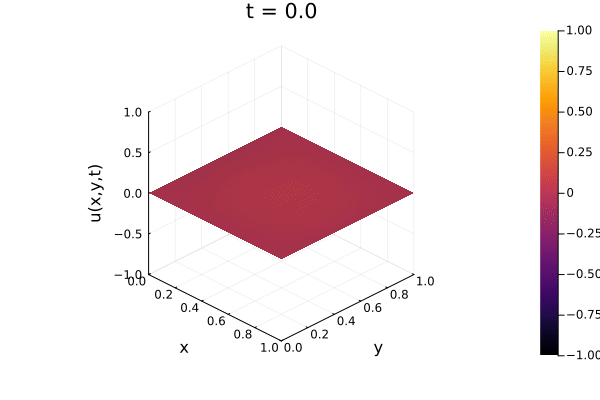

In [ ]:
# EJEMPLO 2 - INESTABLE

a = 1.0
hx = 0.05
hy = 0.05

dt = 0.01
T = 0.4

# Dato inicial
g(x,y) = (x - x^2) * (y - y^2)

# Fuente
f(x,y,t) = 0.0



# SOLUCIÓN NUMÉRICA


@time x, y, sol = explicito_calor(hx, hy, dt, T, a, g, f)



# PARÁMETROS DE INESTABILIDAD


rx = a*dt/hx^2
ry = a*dt/hy^2

println("rx = ", rx)
println("ry = ", ry)
println("rx + ry = ", rx + ry)



# ANIMACIÓN


num_frames = 30

indices = round.(
    Int,
    range(1, size(sol, 3), length=num_frames)
)

anim = @animate for n in indices

    t = (n-1)*dt

    # Solución numérica
    U = sol[:, :, n]

    # Limitamos solamente los valores que mostramos
    # para evitar problemas con números enormes.
    U_grafico = clamp.(U, -1, 1)

    surface(
        x,
        y,
        U_grafico',

        xlabel = "x",
        ylabel = "y",
        zlabel = "u(x,y,t)",

        title = "t = $(round(t, digits=3))",

        # Ejes fijos
        xlims = (0, 1),
        ylims = (0, 1),
        zlims = (-1, 1),

        # Escala de colores fija
        clims = (-1, 1),

        camera = (45, 30),

        label = false
    )

end

gif(anim, "inestabilidad.gif", fps=6)

Ejemplos de estabilidad incondicional del metodo ADI: Usamos los mismos parametros que con el explicito y vemos que para ambos casos el metodo se comporta de manera estable


  0.687020 seconds (703.88 k allocations: 38.015 MiB, 2.03% gc time, 99.22% compilation time: 100% of which was recompilation)
Cálculo terminado
rx = 0.23999999999999994
ry = 0.23999999999999994
rx + ry = 0.47999999999999987


[ Info: Saved animation to /content/estable.gif


Plots.AnimatedGif("/content/estable.gif")
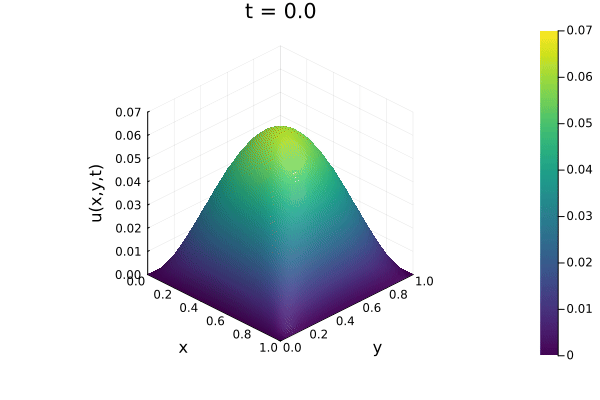

In [ ]:
#EJEMPLO 1
a = 1.0
hx = 0.05
hy = 0.05

dt = 0.0006
T = 0.1

# Dato inicial
g(x,y) = (x - x^2) * (y - y^2)

# Fuente
f(x,y,t) = 0.0


# Solución numérica
@time x, y, sol = ADI_calor(hx, hy, dt, T, a, g, f)

println("Cálculo terminado")


# Parámetros de estabilidad
rx = a*dt/hx^2
ry = a*dt/hy^2

println("rx = ", rx)
println("ry = ", ry)
println("rx + ry = ", rx + ry)


num_frames = 60

indices = round.(
    Int,
    range(1, size(sol, 3), length=num_frames)
)

anim = @animate for n in indices

    t = (n-1)*dt

    surface(
    x,
    y,
    sol[:, :, n]',
    xlabel = "x",
    ylabel = "y",
    zlabel = "u(x,y,t)",
    title = "t = $(round(t, digits=3))",

    xlims = (0, 1),
    ylims = (0, 1),
    zlims = (0, 0.07),

    # Fijo también la escala de colores
    clims = (0, 0.07),

    camera = (45, 30),

    # Para que no se vea casi todo negro
    c = :viridis,

    label = false
)

end

gif(anim, "estable.gif", fps=15)

  0.731022 seconds (693.82 k allocations: 33.021 MiB, 7.05% gc time, 99.84% compilation time: 100% of which was recompilation)
Cálculo terminado
rx = 3.999999999999999
ry = 3.999999999999999
rx + ry = 7.999999999999998


[ Info: Saved animation to /content/estable.gif


Plots.AnimatedGif("/content/estable.gif")
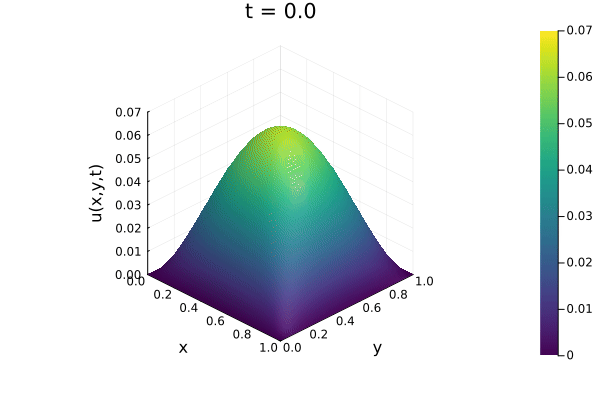

In [ ]:
#EJEMPLO 2
a = 1.0
hx = 0.05
hy = 0.05

dt = 0.01
T = 0.13

# Dato inicial
g(x,y) = (x - x^2) * (y - y^2)

# Fuente
f(x,y,t) = 0.0


# Solución numérica
@time x, y, sol = ADI_calor(hx, hy, dt, T, a, g, f)

println("Cálculo terminado")


# Parámetros de estabilidad
rx = a*dt/hx^2
ry = a*dt/hy^2

println("rx = ", rx)
println("ry = ", ry)
println("rx + ry = ", rx + ry)


num_frames = 60

indices = round.(
    Int,
    range(1, size(sol, 3), length=num_frames)
)

anim = @animate for n in indices

    t = (n-1)*dt

    surface(
    x,
    y,
    sol[:, :, n]',
    xlabel = "x",
    ylabel = "y",
    zlabel = "u(x,y,t)",
    title = "t = $(round(t, digits=3))",

    xlims = (0, 1),
    ylims = (0, 1),
    zlims = (0, 0.07),

    # Fijo también la escala de colores
    clims = (0, 0.07),

    camera = (45, 30),

    # Para que no se vea casi todo negro
    c = :viridis,

    label = false
)

end

gif(anim, "estable.gif", fps=15)

**EJERCICIO 3**

Comparamos primero la solución numérica con la exacta

  0.392616 seconds (345.46 k allocations: 23.264 MiB, 5.63% gc time, 98.98% compilation time: 10% of which was recompilation)


[ Info: Saved animation to c:\Users\mauri\OneDrive\Escritorio\tps_numerico\solucion_ADI.gif


Plots.AnimatedGif("c:\\Users\\mauri\\OneDrive\\Escritorio\\tps_numerico\\solucion_ADI.gif")
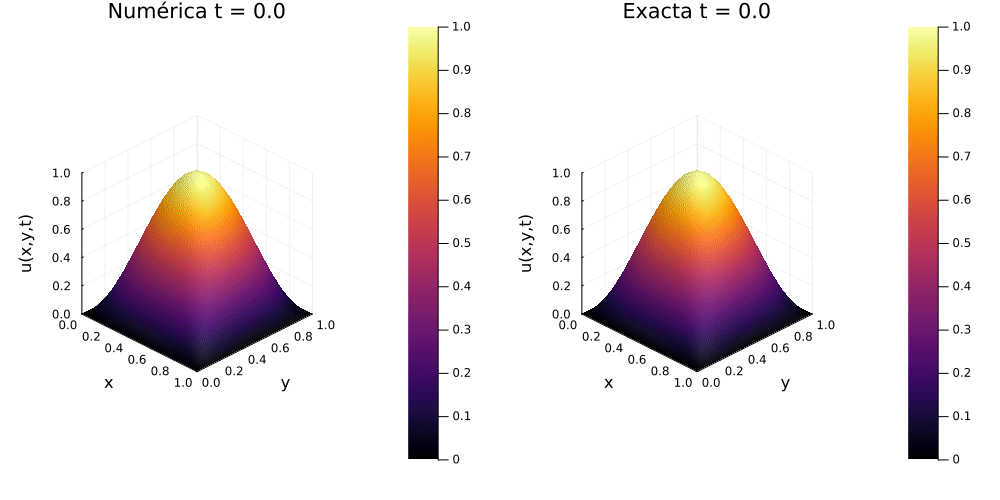

In [7]:
a = 1
λ = 2*(pi^2)
u(x,y,t)=exp(-a*λ*t) * sin(pi*x) * sin(pi*y)
g(x,y)=sin(pi*x) * sin(pi*y)
f(x,y,t)=0

hx = 0.05
hy = 0.05

dt = 0.01
T = 0.2


@time x, y, sol = ADI_calor(hx, hy, dt, T, a, g, f)

anim = @animate for n in 1:size(sol, 3)
    t_actual = (n - 1) * dt

    p1 = surface(
        x,
        y,
        sol[:, :, n]',
        xlabel = "x",
        ylabel = "y",
        zlabel = "u(x,y,t)",
        title = "Numérica t = $(round(t_actual, digits=2))",
        zlims = (0, 1),
        camera = (45, 30)
    )

    sol_exacta = [u(xi, yj, t_actual) for xi in x, yj in y]
    p2 = surface(
        x,
        y,
        sol_exacta',
        xlabel = "x",
        ylabel = "y",
        zlabel = "u(x,y,t)",
        title = "Exacta t = $(round(t_actual, digits=2))",
        zlims = (0, 1),
        camera = (45, 30),
    )

    plot(p1, p2, layout = (1, 2), size = (1000, 500))
end

gif(anim, "solucion_ADI.gif", fps=10)

Ahora aproximamos el orden de los metodos utilizando que
$$ p \approx \frac{\log\big(E(h_i)/E(h_{i+1})\big)}{\log\big(h_i/h_{i+1}\big)} $$

In [8]:
function error_adi(N, dt, T, a, g, f)
  hx = 1 / N
  hy = 1 / N

  x, y, sol = ADI_calor(hx, hy, dt, T, a, g, f)
  t_final = size(sol, 3)
  sol_num = sol[:, :, t_final]'
  sol_ex = [u(xi, yj, T) for xi in x, yj in y]
  error = norm(sol_num - sol_ex, Inf)
  return error, hx
end

function error_explicito(N, dt, T, a, g, f)
  hx = 1 / N
  hy = 1 / N

  x, y, sol = explicito_calor(hx, hy, dt, T, a, g, f)
  t_final = size(sol, 3)
  sol_num = sol[:, :, t_final]'
  sol_ex = [u(xi, yj, T) for xi in x, yj in y]
  error = norm(sol_num - sol_ex, Inf)
  return error, hx
end

function orden_convergencia_adi(dt, T, a, g, f; Ns=[10,20,40,80])
  errores = Float64[]
  hxs = Float64[]
  for N in Ns
    e, hx = error_adi(N, dt, T, a, g, f)
    push!(errores, e)
    push!(hxs, hx)
  end

  ordenes = [log(errores[i]/errores[i+1]) / log(hxs[i]/hxs[i+1]) for i in 1:length(errores)-1]

  println("N\tΔx\t\terror\t\torden estimado")
  for i in eachindex(Ns)
    orden_str = i > 1 ? string(round(ordenes[i-1], digits=3)) : "-"
    println(Ns[i], "\t", round(hxs[i], digits=5), "\t", round(errores[i], sigdigits=4), "\t", orden_str)
  end

  p = plot(hxs, errores, xscale=:log10, yscale=:log10, marker=:circle,
        xlabel="hx (tamaño de malla)", ylabel="Error (norma ∞)",
        label="Método ADI", legend=:topleft,
        title="Orden de convergencia espacial (Δt = $dt fijo)")

  referencia = hxs.^2 .* (errores[1] / hxs[1]^2)
  plot!(p, hxs, referencia, linestyle=:dash, label="O(hx²)")
  display(p)

  return hxs, errores, ordenes
end

function orden_convergencia_explicito(dt, T, a, g, f; Ns=[10,13,17,20])
  errores = Float64[]
  hxs = Float64[]
  for N in Ns
    e, hx = error_explicito(N, dt, T, a, g, f)
    push!(errores, e)
    push!(hxs, hx)
  end

  ordenes = [log(errores[i]/errores[i+1]) / log(hxs[i]/hxs[i+1]) for i in 1:length(errores)-1]

  println("N\tΔx\t\terror\t\torden estimado")
  for i in eachindex(Ns)
    orden_str = i > 1 ? string(round(ordenes[i-1], digits=3)) : "-"
    println(Ns[i], "\t", round(hxs[i], digits=5), "\t", round(errores[i], sigdigits=4), "\t", orden_str)
  end

  p = plot(hxs, errores, xscale=:log10, yscale=:log10, marker=:circle,
        xlabel="hx (tamaño de malla)", ylabel="Error (norma ∞)",
        label="Método explicito", legend=:topleft,
        title="Orden de convergencia espacial (Δt = $dt fijo)")

  referencia = hxs.^2 .* (errores[1] / hxs[1]^2)
  plot!(p, hxs, referencia, linestyle=:dash, label="O(hx²)")
  display(p)

  return hxs, errores, ordenes
end

orden_convergencia_explicito (generic function with 1 method)

Luego obtenemos que ambos metodos son de orden 2

N	Δx		error		orden estimado
10	0.1	0.0006191	-
20	0.05	0.0001417	2.128
40	0.025	2.372e-5	2.578
80	0.0125	5.669e-6	2.065


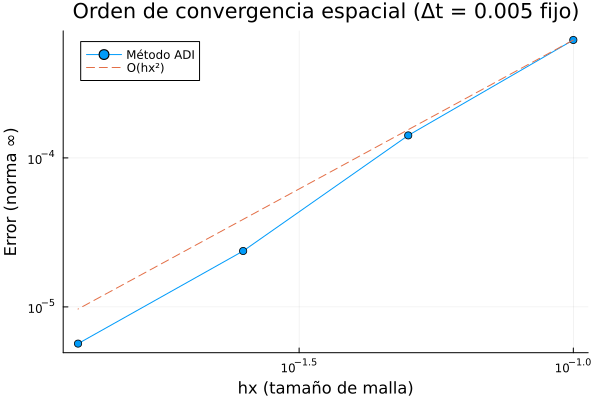

N	Δx		error		orden estimado
10	0.1	0.0006271	-
13	0.07692	0.0003607	2.108
17	0.05882	0.0002084	2.044
20	0.05	0.0001496	2.041


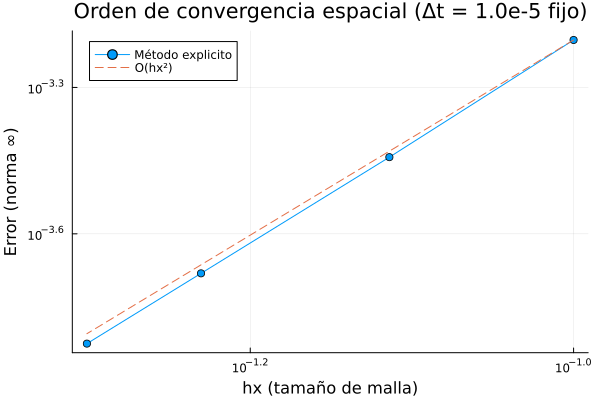

([0.1, 0.07692307692307693, 0.058823529411764705, 0.05], [0.0006270639744347974, 0.00036067923760822393, 0.00020842126790293972, 0.00014959573789728384], [2.1079835101577293, 2.0443581484033806, 2.0405301944265015])

In [9]:
orden_convergencia_adi(0.005,0.2,a,g,f)

#el metodo ADI es de orden 2

orden_convergencia_explicito(0.00001,0.2,a,g,f)

#el metodo explícito es de orden 2